# RQ3 Analysis: Measure of Textual Lexical Diversity (MTLD)

Compares the lexical diversity (MTLD) of human-written vs. LLM-generated PR descriptions.

- Uses **TAALED** (Tool for the Automatic Analysis of Lexical Diversity) to compute MTLD.
- MTLD = mean length of sequential word strings that maintain a TTR ≥ 0.72 (McCarthy & Jarvis, 2010).
- Reports both **MTLD Original** (`mtldo` — forward-only) and **MTLD Bidirectional** (`mtld` — average of forward + backward).
- Uses `nltk.word_tokenize` for tokenization (consistent with TTR notebook).
- Compares across models and prompt context variations.

**Reference:** McCarthy, P. M., & Jarvis, S. (2010). MTLD, vocd-D, and HD-D: A validation study of sophisticated approaches to lexical diversity assessment. *Behavior Research Methods*, 42(2), 381–392.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.tokenize import word_tokenize
from scipy.stats import mannwhitneyu, kruskal
import paired_stats as PS  # Tier-A shared helpers: paired Wilcoxon, FDR, effect sizes
import scikit_posthocs as sp
import taaled


plotnine has not been installed.
To enable advanced data visualization features, please install plotnine.


In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
csv_path = '../datasets/temperature_1/run_3_cleaned/detection_results.csv'
df = pd.read_csv(csv_path)

In [4]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [5]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [6]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

In [7]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

In [8]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: <StringArray>
['meta-llama/llama-3.1-70b-instruct',             'gpt-5-mini-2025-08-07',
         'Qwen/Qwen2.5-72B-Instruct']
Length: 3, dtype: str
Human entries: 308, AI entries: 5526


## 2. Compute MTLD using TAALED

TAALED's `lexdiv` class computes multiple MTLD variants:
- **`mtldo`** — Original MTLD (forward-only pass; McCarthy & Jarvis, 2010)
- **`mtld`** / **`mtldav`** — Bidirectional MTLD (average of forward + backward passes)

We use `nltk.word_tokenize` for tokenization (consistent with the TTR notebook) and pass lowercased tokens to TAALED. Texts with fewer than 10 tokens are excluded as MTLD is unreliable for very short texts.

In [9]:
def compute_mtld(text: str) -> dict:
    if pd.isna(text) or str(text).strip() == '':
        return {'mtld_original': np.nan, 'mtld_bidir': np.nan}
    tokens = word_tokenize(str(text).lower())
    if len(tokens) < 10:
        return {'mtld_original': np.nan, 'mtld_bidir': np.nan}
    try:
        ld = taaled.lexdiv(tokens)
        return {'mtld_original': ld.mtldo, 'mtld_bidir': ld.mtld}
    except Exception:
        return {'mtld_original': np.nan, 'mtld_bidir': np.nan}


In [10]:
# Apply to both subsets
human_mtld = human_df['text'].apply(compute_mtld).apply(pd.Series)
human_df = pd.concat([human_df, human_mtld], axis=1)

ai_mtld = ai_df['text'].apply(compute_mtld).apply(pd.Series)
ai_df = pd.concat([ai_df, ai_mtld], axis=1)

In [11]:
# Combine for analysis
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
combined_df['source'] = combined_df['entry_type'].map({'human': 'Human', 'ai': 'AI'})
combined_df = combined_df.dropna(subset=['mtld_original'])

In [12]:
print("MTLD metrics computed.")
print(f"Combined dataset size: {len(combined_df)}")
display(combined_df[['entry_type', 'model', 'text', 'mtld_original', 'mtld_bidir']].head(10))

MTLD metrics computed.
Combined dataset size: 5715


,entry_type,model,text,mtld_original,mtld_bidir
0,human,Human,Fixes #8873 \r\n\r\n\r\n<!-- \r\n- Go through ...,47.474312,49.489630
1,human,Human,"Implements #1516. Selected fields (`ISBN`, `UR...",20.333333,24.200000
2,human,Human,"Fixes #8108 \r\n\r\nTheoretically works, but n...",54.820163,56.829911
3,human,Human,Fixes #3905\r\n\r\n<!-- describe the changes y...,43.122664,47.588500
5,human,Human,Fixes #8654\r\nThis allows for the right click...,54.399691,55.806815
6,human,Human,# Changed database structure: table names are ...,35.712130,37.353500
7,human,Human,See #2789.\r\n> JabRef version 4.0.0-beta on W...,77.440000,77.440000
8,human,Human,Fixes #3584\r\n\r\n(No changelod needed as thi...,47.434293,65.506667
9,human,Human,…tting down\r\n\r\nFixes #2486. Unregistering ...,87.808000,87.808000
10,human,Human,Fix #1776 remove Cookie Handler implementation...,125.692000,125.692000


## 3. Descriptive Statistics: Human vs AI (Overall)

In [13]:
print(f"\n{'='*60}")
print("  MTLD (Original) — Descriptive Statistics")
print(f"{'='*60}")


  MTLD (Original) — Descriptive Statistics


In [14]:
stats = combined_df.groupby('source')['mtld_original'].describe()
stats['median'] = combined_df.groupby('source')['mtld_original'].median()
display(stats)

,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5418.0,67.114053,26.554851,0.0,51.000000,65.265219,81.000000,304.92,65.265219
Human,297.0,57.859436,20.701365,0.0,47.272677,54.399691,65.248843,189.28,54.399691


In [15]:
for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['mtld_original']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.4f}, Median={vals.median():.4f}, Q3={q3:.4f}, IQR={q3 - q1:.4f}")

print()
print(f"{'='*60}")
print("  MTLD (Bidirectional) — Descriptive Statistics")
print(f"{'='*60}")

for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['mtld_bidir']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.4f}, Median={vals.median():.4f}, Q3={q3:.4f}, IQR={q3 - q1:.4f}")

  Human: Q1=47.2727, Median=54.3997, Q3=65.2488, IQR=17.9762
  AI: Q1=51.0000, Median=65.2652, Q3=81.0000, IQR=30.0000

  MTLD (Bidirectional) — Descriptive Statistics
  Human: Q1=48.1680, Median=57.7875, Q3=67.5968, IQR=19.4288
  AI: Q1=51.3308, Median=65.4855, Q3=81.3120, IQR=29.9812


## 4. Descriptive Statistics: By Model

In [16]:
print(f"\n{'='*60}")
print("  MTLD (Original) — By Model")
print(f"{'='*60}")


  MTLD (Original) — By Model


In [17]:
stats_model = combined_df.groupby('model')['mtld_original'].describe()
stats_model['Median'] = combined_df.groupby('model')['mtld_original'].median()
stats_model['Q1'] = combined_df.groupby('model')['mtld_original'].quantile(0.25)
stats_model['Q3'] = combined_df.groupby('model')['mtld_original'].quantile(0.75)
stats_model['IQR'] = stats_model['Q3'] - stats_model['Q1']

In [18]:
display(stats_model[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(
    columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}
))

,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,297.0,57.859436,20.701365,54.399691,47.272677,65.248843,17.976166
Qwen/Qwen2.5-72B-Instruct,1842.0,66.079681,22.420717,63.636364,51.000000,77.538462,26.538462
gpt-5-mini-2025-08-07,1842.0,77.119067,18.687266,75.489822,64.026656,87.851156,23.824501
meta-llama/llama-3.1-70b-instruct,1734.0,57.584684,33.178266,53.760000,39.474785,69.776667,30.301882


In [19]:
print(f"\n{'='*60}")
print("  MTLD (Bidirectional) — By Model")
print(f"{'='*60}")

stats_model_bi = combined_df.groupby('model')['mtld_bidir'].describe()
stats_model_bi['Median'] = combined_df.groupby('model')['mtld_bidir'].median()
stats_model_bi['Q1'] = combined_df.groupby('model')['mtld_bidir'].quantile(0.25)
stats_model_bi['Q3'] = combined_df.groupby('model')['mtld_bidir'].quantile(0.75)
stats_model_bi['IQR'] = stats_model_bi['Q3'] - stats_model_bi['Q1']

display(stats_model_bi[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(
    columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}
))


  MTLD (Bidirectional) — By Model


,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,297.0,59.851321,21.201985,57.787500,48.168000,67.596800,19.428800
Qwen/Qwen2.5-72B-Instruct,1842.0,66.474131,22.626699,63.859333,51.580738,78.098333,26.517595
gpt-5-mini-2025-08-07,1842.0,77.392739,19.278665,75.049365,63.754872,87.881542,24.126670
meta-llama/llama-3.1-70b-instruct,1734.0,57.630663,33.570626,53.816000,38.934000,70.108158,31.174158


## 5. Statistical Testing & Effect Size

In [20]:
def cliffs_delta(lst1: list, lst2: list) -> float:
    """Compute Cliff's Delta effect size."""
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y: dom += 1
            elif x < y: dom -= 1
    return dom / (m * n)

In [21]:
def interpret_cliffs_delta(d: float) -> str:
    d = abs(d)
    if d < 0.147: return "Negligible"
    elif d < 0.33: return "Small"
    elif d < 0.474: return "Medium"
    else: return "Large"

In [22]:
model_results = []

In [23]:
human_mtld_orig = combined_df[combined_df['source'] == 'Human']['mtld_original'].values
human_mtld_bi = combined_df[combined_df['source'] == 'Human']['mtld_bidir'].values

In [24]:
# Per-model OVERALL comparison (PAIRED, per-PR mean across contexts) -- Tier-A.
# Replaces independent-samples Mann-Whitney U on paired human/AI data. For each model,
# summarise its six-context output per PR as the mean, then pair against the human value
# for the same PR (Wilcoxon signed-rank). Effect sizes: Cliff's delta (dominance) +
# matched-pairs rank-biserial. FDR (BH) applied within each metric. See paired_stats.py.
models = ai_df['model'].unique()
model_results = []
for _col, _label in [('mtld_original', 'MTLD Original'), ('mtld_bidir', 'MTLD Bidirectional')]:
    _ai_all = ai_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _hu_all = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _m = pd.concat([_hu_all.rename('h'), _ai_all.rename('a')], axis=1, join='inner').dropna()
    _r = PS.paired_test(_m['h'].values, _m['a'].values)
    print("[%s] pooled Human vs AI (paired): n=%d, Wilcoxon p=%.3g, Cliff's d=%.4f (%s)"
          % (_label, _r['n'], _r['p'], _r['cliffs_delta'], _r['magnitude']))
    for _model in ai_df['model'].unique():
        _ai_pr = ai_df[ai_df['model'] == _model].dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _hu_pr = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _merged = pd.concat([_hu_pr.rename('h'), _ai_pr.rename('a')], axis=1, join='inner').dropna()
        _r = PS.paired_test(_merged['h'].values, _merged['a'].values)
        model_results.append({
            'Model': _model, 'Metric': _label, 'N pairs': _r['n'],
            'Human Median': _r['median_human'], 'Model Median': _r['median_ai'],
            'Wilcoxon p': _r['p'], "Cliff's Delta": round(_r['cliffs_delta'], 4),
            'Rank-Biserial': round(_r['rank_biserial'], 4), 'Effect Size': _r['magnitude'],
        })
model_results_df = pd.DataFrame(model_results)
model_results_df = PS.apply_fdr_by(model_results_df, 'Metric', pcol='Wilcoxon p')
model_results_df['Sig'] = model_results_df['adj_Wilcoxon p'].apply(PS.sig_mark)
display(model_results_df)


[MTLD Original] pooled Human vs AI (paired): n=297, Wilcoxon p=8.7e-22, Cliff's d=-0.5315 (Large)
[MTLD Bidirectional] pooled Human vs AI (paired): n=297, Wilcoxon p=8.07e-17, Cliff's d=-0.4403 (Medium)


,Model,Metric,N pairs,Human Median,Model Median,Wilcoxon p,Cliff's Delta,Rank-Biserial,Effect Size,adj_Wilcoxon p,sig,Sig
0,meta-llama/llama-3.1-70b-instruct,MTLD Original,297,54.399691,55.987269,2.272797e-01,-0.0590,-0.0808,Negligible,2.272797e-01,False,n.s.
1,gpt-5-mini-2025-08-07,MTLD Original,297,54.399691,76.573262,1.741965e-37,-0.7617,-0.8566,Large,5.225895e-37,True,***
2,Qwen/Qwen2.5-72B-Instruct,MTLD Original,297,54.399691,65.988381,3.165368e-17,-0.4629,-0.5650,Medium,4.748052e-17,True,***
3,meta-llama/llama-3.1-70b-instruct,MTLD Bidirectional,297,57.787500,55.892559,6.252477e-01,0.0259,0.0327,Negligible,6.252477e-01,False,n.s.
4,gpt-5-mini-2025-08-07,MTLD Bidirectional,297,57.787500,76.873474,1.333399e-34,-0.7127,-0.8213,Large,4.000198e-34,True,***
5,Qwen/Qwen2.5-72B-Instruct,MTLD Bidirectional,297,57.787500,66.064177,1.513564e-12,-0.3760,-0.4735,Medium,2.270346e-12,True,***


In [25]:
models = ai_df['model'].unique()

In [26]:
print(models)
display(model_results_df)  # Tier-A: reuse FDR-corrected per-model table built above


<StringArray>
['meta-llama/llama-3.1-70b-instruct',             'gpt-5-mini-2025-08-07',
         'Qwen/Qwen2.5-72B-Instruct']
Length: 3, dtype: str


,Model,Metric,N pairs,Human Median,Model Median,Wilcoxon p,Cliff's Delta,Rank-Biserial,Effect Size,adj_Wilcoxon p,sig,Sig
0,meta-llama/llama-3.1-70b-instruct,MTLD Original,297,54.399691,55.987269,2.272797e-01,-0.0590,-0.0808,Negligible,2.272797e-01,False,n.s.
1,gpt-5-mini-2025-08-07,MTLD Original,297,54.399691,76.573262,1.741965e-37,-0.7617,-0.8566,Large,5.225895e-37,True,***
2,Qwen/Qwen2.5-72B-Instruct,MTLD Original,297,54.399691,65.988381,3.165368e-17,-0.4629,-0.5650,Medium,4.748052e-17,True,***
3,meta-llama/llama-3.1-70b-instruct,MTLD Bidirectional,297,57.787500,55.892559,6.252477e-01,0.0259,0.0327,Negligible,6.252477e-01,False,n.s.
4,gpt-5-mini-2025-08-07,MTLD Bidirectional,297,57.787500,76.873474,1.333399e-34,-0.7127,-0.8213,Large,4.000198e-34,True,***
5,Qwen/Qwen2.5-72B-Instruct,MTLD Bidirectional,297,57.787500,66.064177,1.513564e-12,-0.3760,-0.4735,Medium,2.270346e-12,True,***


## 6. Visualizations

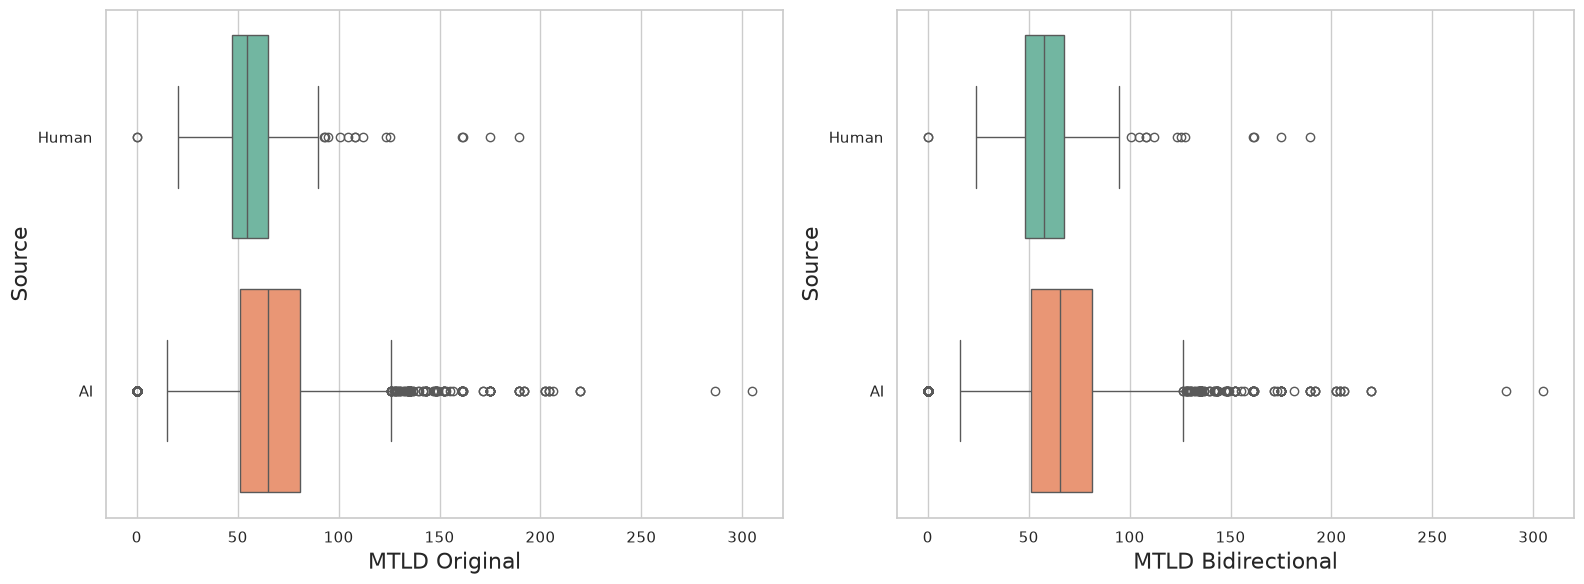

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=combined_df, x='mtld_original', y='source', hue='source',
            palette='Set2', legend=False, ax=axes[0])
axes[0].set_xlabel("MTLD Original", fontsize=16)
axes[0].set_ylabel("Source", fontsize=16)

sns.boxplot(data=combined_df, x='mtld_bidir', y='source', hue='source',
            palette='Set2', legend=False, ax=axes[1])
axes[1].set_xlabel("MTLD Bidirectional", fontsize=16)
axes[1].set_ylabel("Source", fontsize=16)

plt.tight_layout()
plt.show()

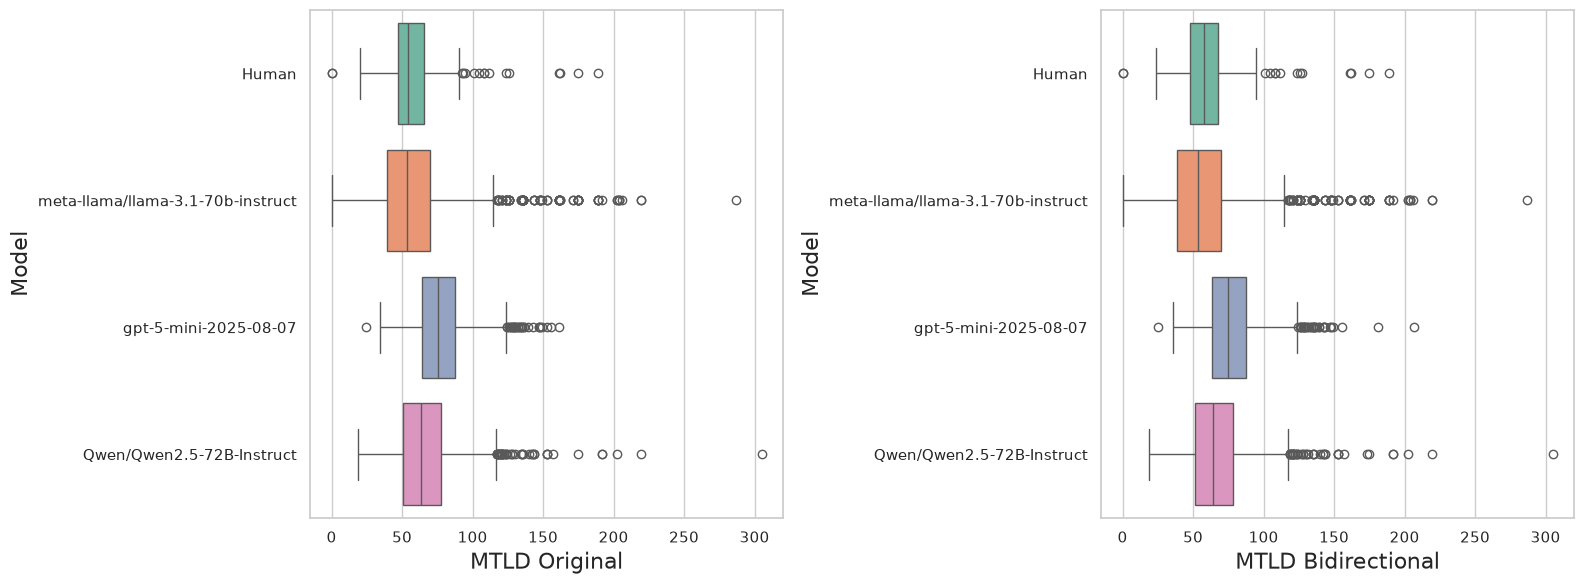

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

order = ['Human'] + list(models)

sns.boxplot(data=combined_df, x='mtld_original', y='model', order=order,
            hue='model', palette='Set2', legend=False, ax=axes[0])
axes[0].set_xlabel("MTLD Original", fontsize=16)
axes[0].set_ylabel("Model", fontsize=16)

sns.boxplot(data=combined_df, x='mtld_bidir', y='model', order=order,
            hue='model', palette='Set2', legend=False, ax=axes[1])
axes[1].set_xlabel("MTLD Bidirectional", fontsize=16)
axes[1].set_ylabel("Model", fontsize=16)

plt.tight_layout()
plt.show()

## 7. MTLD Boxplots by Context per LLM (with Human Baseline)

This mirrors the word-count, sentence-count, FKGL, and TTR setup:

- One panel per LLM model (stacked vertically).
- Each panel includes 6 AI context boxplots.
- A Human baseline boxplot is included in each panel for direct comparison.
- Rendered for both MTLD variants: `mtld_original` and `mtld_bidir`.

In [29]:
print(f"\n{'='*60}")
print("  MTLD (Original) — By Prompt Context Variation")
print(f"{'='*60}")


  MTLD (Original) — By Prompt Context Variation


In [30]:
# Filter to only AI data since 'human' entries don't have variation context
context_df = combined_df[combined_df['source'] == 'AI'].copy()
stats_ctx = context_df.groupby('Context_Name')['mtld_original'].describe()
stats_ctx['median'] = context_df.groupby('Context_Name')['mtld_original'].median()
display(stats_ctx)

,count,mean,std,min,25%,50%,75%,max,median
Context_Name,,,,,,,,,
File Contents,897.0,62.048769,21.547588,0.0,47.017857,60.501538,75.054523,136.786087,60.501538
File Diff,914.0,61.195967,24.856239,0.0,46.959315,59.583506,73.927523,206.173333,59.583506
Linked Issue,923.0,74.027796,24.970004,0.0,58.394155,71.384733,87.372811,219.520000,71.384733
PR Title,922.0,77.503638,35.558179,0.0,60.480000,74.666667,91.659091,304.920000,74.666667
Repo Path,845.0,61.788711,24.913487,0.0,44.535540,61.500000,77.069323,161.146770,61.500000
Without File Contents,917.0,65.469582,19.587051,0.0,52.110527,63.806902,78.529630,136.080000,63.806902


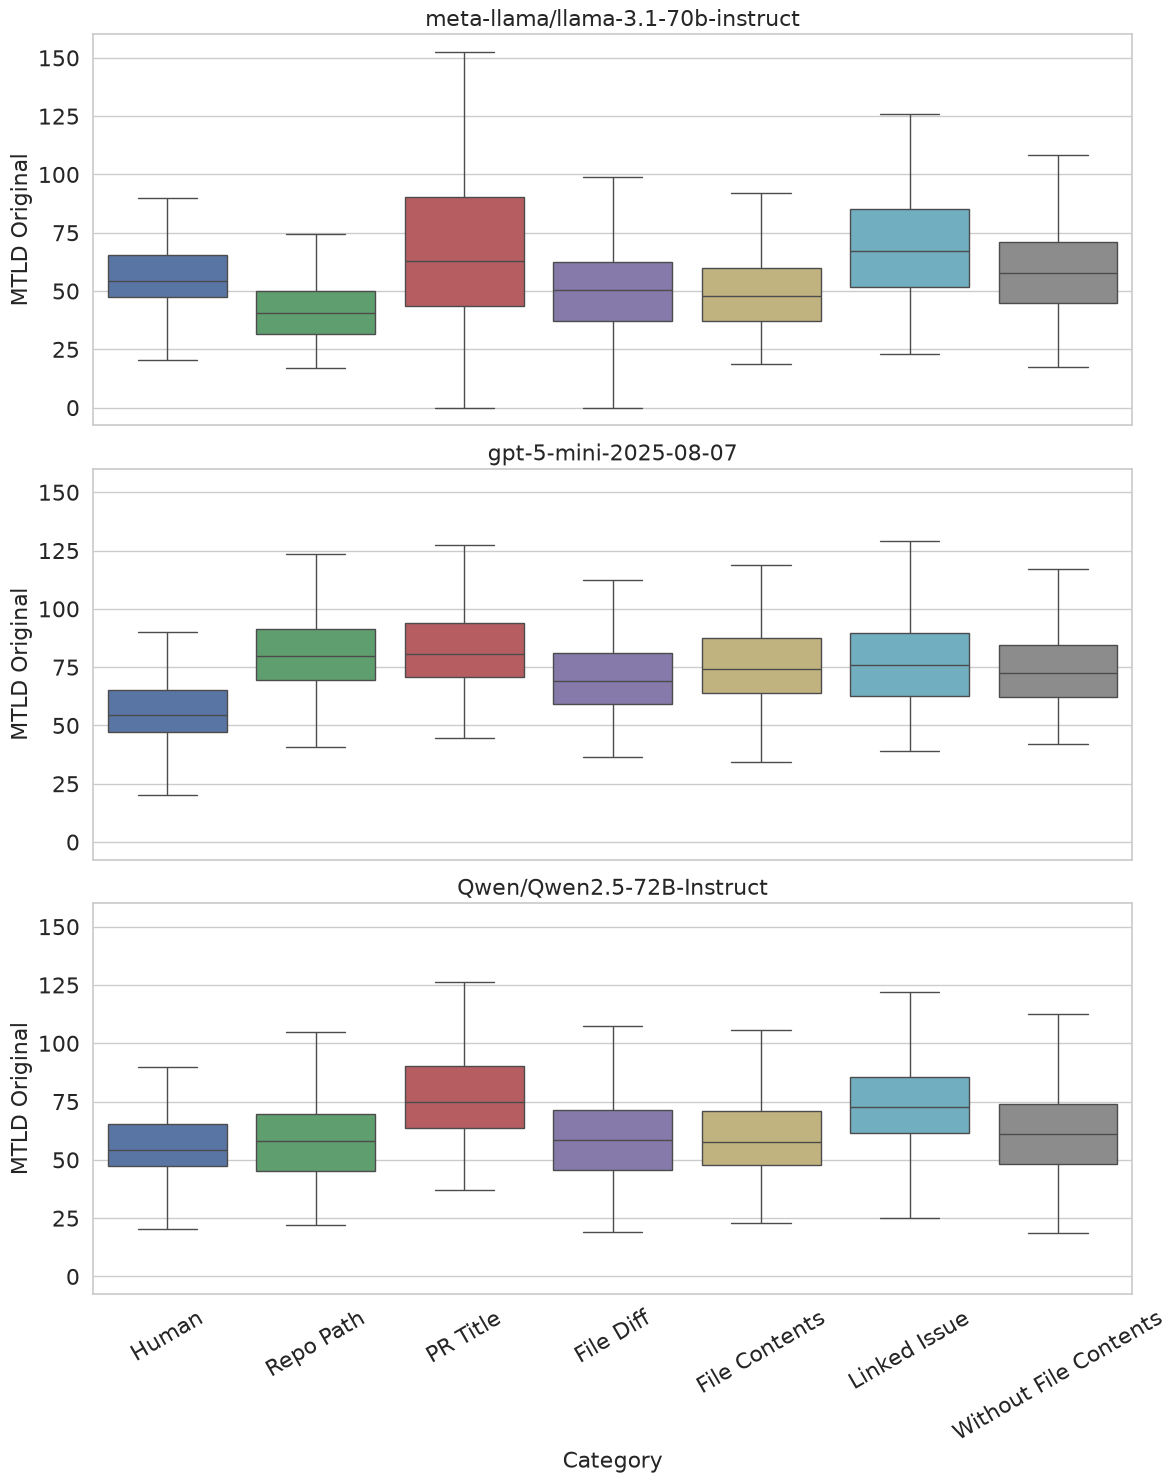

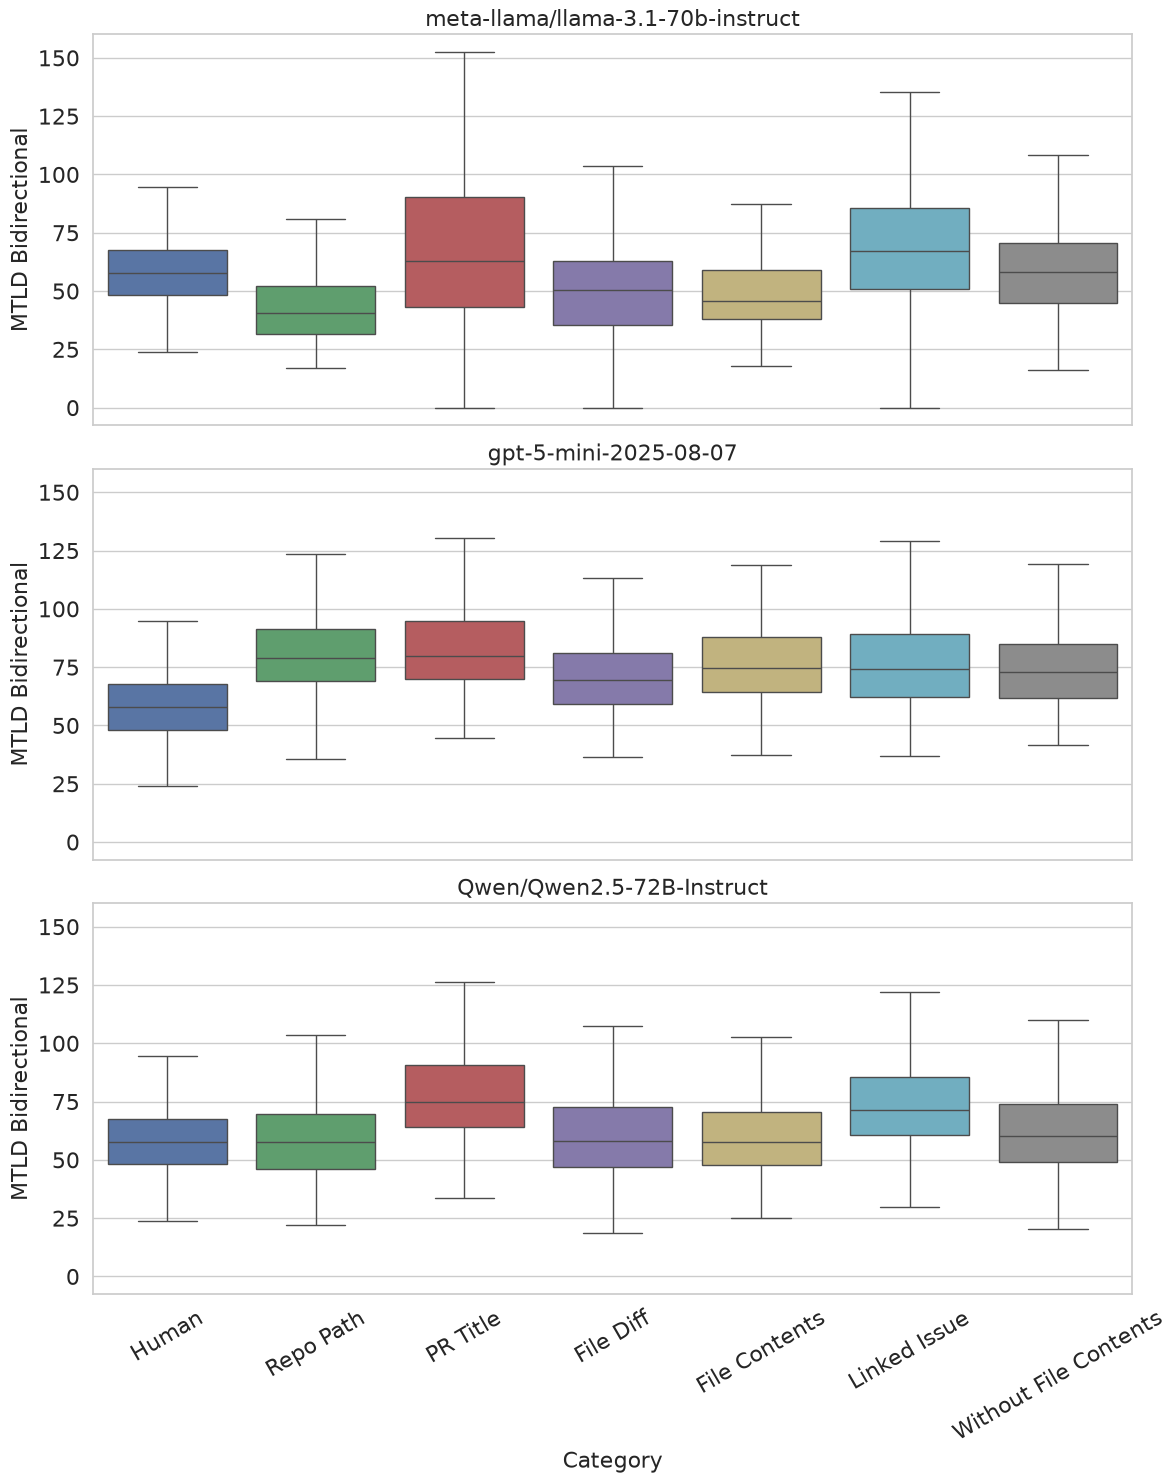

In [31]:
from pathlib import Path
OUT_DIR = Path('outputs/figures_pdf')
OUT_DIR.mkdir(parents=True, exist_ok=True)
context_order = [
    'Repo Path',
    'PR Title',
    'File Diff',
    'File Contents',
    'Linked Issue',
    'Without File Contents'
]

llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

def plot_mtld_by_context(metric_col: str, y_label: str, figure_title: str) -> None:
    fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)

    if len(llm_models) == 1:
        axes = [axes]

    for i, model in enumerate(llm_models):
        ax = axes[i]
        ax.set_title(model, fontsize=16)

        ai_slice = ai_df[ai_df['model'] == model][[metric_col, 'Context_Name']].dropna().copy()
        ai_slice['Category'] = ai_slice['Context_Name']

        human_slice = human_df[[metric_col]].dropna().copy()
        human_slice['Category'] = 'Human'

        panel_df = pd.concat([
            human_slice[[metric_col, 'Category']],
            ai_slice[[metric_col, 'Category']]
        ], ignore_index=True)

        sns.boxplot(
            data=panel_df,
            x='Category',
            y=metric_col,
            order=x_order,
            hue='Category',
            hue_order=x_order,
            ax=ax,
            palette=palette_map,
            dodge=False,
            legend=False,
            showfliers=False
        )

        ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=16)
        ax.set_ylabel(y_label, fontsize=16)
        ax.tick_params(axis='x', rotation=30, labelsize=16)
        ax.tick_params(axis='y', labelsize=16)

    plt.tight_layout()
    plt.savefig(str(OUT_DIR / (figure_title.replace(' ', '_').replace(':', '') + '.pdf')), bbox_inches='tight', dpi=150)
    plt.show()

plot_mtld_by_context('mtld_original', 'MTLD Original', 'MTLD Original Distribution: Human vs Contexts')
plot_mtld_by_context('mtld_bidir', 'MTLD Bidirectional', 'MTLD Bidirectional Distribution: Human vs Contexts')

## 8. Human vs. AI Context Variations (Cliff's δ Effect Sizes per Model)

For each model and each prompt context variation, we compare the paired Human descriptions against the AI-generated descriptions using Cliff's δ effect size measure for MTLD.

In [32]:
print(f"\n{'='*90}")
print("  Cliff's δ Effect Sizes: Human vs. AI Context Variations (MTLD)")
print(f"{'='*90}")


  Cliff's δ Effect Sizes: Human vs. AI Context Variations (MTLD)


In [33]:
model_names = ai_df['model'].unique()
variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

In [34]:
# Human vs. AI per context (PAIRED): Cliff's delta + Wilcoxon signed-rank, BH-FDR -- Tier-A.
# Filter by the stable variation code (P-1..P-6); display labels differ across notebooks
# ('File Diff' vs 'PR Diffs', 'Linked Issue' vs 'Related Issues'), so the code is the safe key.
import os as _os
VARIATION_TO_CTX = {'P-1': 'Repo Path', 'P-2': 'PR Title', 'P-3': 'File Diff', 'P-4': 'File Contents', 'P-5': 'Linked Issue', 'P-6': 'Without File Contents'}
variation_codes = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
variation_names = [VARIATION_TO_CTX[_p] for _p in variation_codes]
_long = []
for _col, _label in [('mtld_original', 'MTLD Original'), ('mtld_bidir', 'MTLD Bidirectional')]:
    for _model in ai_df['model'].unique():
        for _pcode in variation_codes:
            _slice = ai_df[(ai_df['model'] == _model) & (ai_df['variation'] == _pcode)]
            _r = PS.paired_test_from_frames(human_df, _slice, _col, key='normalized_pr_id')
            _long.append({'Metric': _label, 'Model': _model, 'Context': VARIATION_TO_CTX[_pcode],
                          'n': _r['n'], 'cliffs_delta': _r['cliffs_delta'], 'magnitude': _r['magnitude'],
                          'rank_biserial': _r['rank_biserial'], 'p': _r['p']})
long_df = PS.apply_fdr_by(pd.DataFrame(_long), 'Metric', pcol='p')
long_df['Sig'] = long_df['adj_p'].apply(PS.sig_mark)
_os.makedirs('outputs', exist_ok=True)
long_df.to_csv('outputs/rq2_mtld_paired_stats.csv', index=False)
print('Saved tidy paired stats -> outputs/rq2_mtld_paired_stats.csv')

def _fmt_cell(x):
    return "%.3f (%s) %s" % (x['cliffs_delta'], x['magnitude'][0], x['Sig'])
context_tables = {}
for _col, _label in [('mtld_original', 'MTLD Original'), ('mtld_bidir', 'MTLD Bidirectional')]:
    _sub = long_df[long_df['Metric'] == _label].copy()
    _sub['cell'] = _sub.apply(_fmt_cell, axis=1)
    _piv = _sub.pivot(index='Model', columns='Context', values='cell').reindex(columns=variation_names)
    context_tables[_label] = _piv
    print("\n=== %s: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===" % _label)
    display(_piv)
result_df = list(context_tables.values())[-1]
effect_df = list(context_tables.values())[-1]
result_orig_df = context_tables['MTLD Original']
result_bidir_df = context_tables['MTLD Bidirectional']


Saved tidy paired stats -> outputs/rq2_mtld_paired_stats.csv

=== MTLD Original: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===


Context,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
Qwen/Qwen2.5-72B-Instruct,-0.044 (N) n.s.,-0.616 (L) ***,-0.094 (N) *,-0.138 (N) *,-0.542 (L) ***,-0.190 (S) ***
gpt-5-mini-2025-08-07,-0.726 (L) ***,-0.726 (L) ***,-0.497 (L) ***,-0.600 (L) ***,-0.603 (L) ***,-0.593 (L) ***
meta-llama/llama-3.1-70b-instruct,0.535 (L) ***,-0.157 (S) **,0.203 (S) ***,0.264 (S) ***,-0.325 (S) ***,-0.069 (N) n.s.



=== MTLD Bidirectional: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===


Context,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
Qwen/Qwen2.5-72B-Instruct,0.024 (N) n.s.,-0.566 (L) ***,-0.061 (N) n.s.,-0.044 (N) n.s.,-0.464 (M) ***,-0.129 (N) **
gpt-5-mini-2025-08-07,-0.664 (L) ***,-0.668 (L) ***,-0.434 (M) ***,-0.550 (L) ***,-0.529 (L) ***,-0.539 (L) ***
meta-llama/llama-3.1-70b-instruct,0.562 (L) ***,-0.114 (N) *,0.251 (S) ***,0.354 (M) ***,-0.254 (S) ***,-0.008 (N) n.s.


In [35]:
print("MTLD Original -- Cliff's delta by Model x Context (paired Wilcoxon, BH-FDR):")
display(result_orig_df)
print("\nMTLD Bidirectional -- Cliff's delta by Model x Context (paired Wilcoxon, BH-FDR):")
display(result_bidir_df)  # Tier-A: reuse paired per-context tables built above


MTLD Original -- Cliff's delta by Model x Context (paired Wilcoxon, BH-FDR):


Context,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
Qwen/Qwen2.5-72B-Instruct,-0.044 (N) n.s.,-0.616 (L) ***,-0.094 (N) *,-0.138 (N) *,-0.542 (L) ***,-0.190 (S) ***
gpt-5-mini-2025-08-07,-0.726 (L) ***,-0.726 (L) ***,-0.497 (L) ***,-0.600 (L) ***,-0.603 (L) ***,-0.593 (L) ***
meta-llama/llama-3.1-70b-instruct,0.535 (L) ***,-0.157 (S) **,0.203 (S) ***,0.264 (S) ***,-0.325 (S) ***,-0.069 (N) n.s.



MTLD Bidirectional -- Cliff's delta by Model x Context (paired Wilcoxon, BH-FDR):


Context,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
Qwen/Qwen2.5-72B-Instruct,0.024 (N) n.s.,-0.566 (L) ***,-0.061 (N) n.s.,-0.044 (N) n.s.,-0.464 (M) ***,-0.129 (N) **
gpt-5-mini-2025-08-07,-0.664 (L) ***,-0.668 (L) ***,-0.434 (M) ***,-0.550 (L) ***,-0.529 (L) ***,-0.539 (L) ***
meta-llama/llama-3.1-70b-instruct,0.562 (L) ***,-0.114 (N) *,0.251 (S) ***,0.354 (M) ***,-0.254 (S) ***,-0.008 (N) n.s.


## 9. Summary Table

In [36]:
summary_rows = []

In [37]:
for model in combined_df['model'].unique():
    subset = combined_df[combined_df['model'] == model]

    for metric, col in [('MTLD Original', 'mtld_original'), ('MTLD Bidirectional', 'mtld_bidir')]:
        vals = subset[col].dropna()
        summary_rows.append({
            'Model': model,
            'Metric': metric,
            'N': len(vals),
            'Mean': round(vals.mean(), 4),
            'Median': round(vals.median(), 4),
            'Std': round(vals.std(), 4),
            'Min': round(vals.min(), 4),
            'Max': round(vals.max(), 4),
            'Q1': round(vals.quantile(0.25), 4),
            'Q3': round(vals.quantile(0.75), 4)
        })

In [38]:
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,MTLD Original,297,57.8594,54.3997,20.7014,0.0000,189.2800,47.2727,65.2488
1,Human,MTLD Bidirectional,297,59.8513,57.7875,21.2020,0.0000,189.2800,48.1680,67.5968
2,meta-llama/llama-3.1-70b-instruct,MTLD Original,1734,57.5847,53.7600,33.1783,0.0000,286.7200,39.4748,69.7767
3,meta-llama/llama-3.1-70b-instruct,MTLD Bidirectional,1734,57.6307,53.8160,33.5706,0.0000,286.7200,38.9340,70.1082
4,gpt-5-mini-2025-08-07,MTLD Original,1842,77.1191,75.4898,18.6873,24.6339,161.1468,64.0267,87.8512
5,gpt-5-mini-2025-08-07,MTLD Bidirectional,1842,77.3927,75.0494,19.2787,25.3706,206.3778,63.7549,87.8815
6,Qwen/Qwen2.5-72B-Instruct,MTLD Original,1842,66.0797,63.6364,22.4207,18.6660,304.9200,51.0000,77.5385
7,Qwen/Qwen2.5-72B-Instruct,MTLD Bidirectional,1842,66.4741,63.8593,22.6267,18.5000,304.9200,51.5807,78.0983


In [39]:
import os
os.makedirs('outputs', exist_ok=True)

# Save summary to CSV
summary_df.to_csv('outputs/rq3_mtld_summary.csv', index=False)
print("\nSummary saved to outputs/rq3_mtld_summary.csv")


Summary saved to outputs/rq3_mtld_summary.csv
